In [1]:
import os
from pathlib import Path

# Walk up until we find the repo root (identified by CLAUDE.md)
_here = Path(os.getcwd())
while not (_here / "CLAUDE.md").exists() and _here != _here.parent:
    _here = _here.parent
os.chdir(_here)
del _here

import duckdb
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import statsmodels.formula.api as smf
from scipy.stats import sem

%matplotlib inline

Path("results").mkdir(exist_ok=True)
Path("results/plots").mkdir(exist_ok=True)

DARK  = "#2c3e50"; MID  = "#7f8c8d"; GOLD  = "#e8b84b"
RED   = "#e74c3c"; BLUE = "#3498db"; GREEN = "#27ae60"; BG = "#f8f8f8"

MIN_SWINGS = 200
COMMIT_MS  = 150

# Empirical baseline columns: expected plate location from KNN on commit-time state
EMP_DEV_X   = f"pc{COMMIT_MS}_emp_dev_x"    # actual - KNN-expected plate_x
EMP_DEV_Z   = f"pc{COMMIT_MS}_emp_dev_z"    # actual - KNN-expected plate_z
EMP_X_PROJ  = f"pc{COMMIT_MS}_emp_x_proj"   # KNN-expected plate_x
EMP_Z_PROJ  = f"pc{COMMIT_MS}_emp_z_proj"   # KNN-expected plate_z

# Gravity-corrected linear deviation (spin-induced only, gravity stripped out)
LIN_DEV_X   = f"pc{COMMIT_MS}_dev_x"
LIN_DEV_Z   = f"pc{COMMIT_MS}_dev_z"

# Primary treatment columns used throughout (empirical baseline)
DEV_X = EMP_DEV_X
DEV_Z = EMP_DEV_Z

AXIS_COLS  = ("vert_attack_angle_dev", "horz_attack_angle_dev", "swing_path_tilt_dev")
AXIS_LBL   = {"vert_attack_angle_dev": "VAA",
              "horz_attack_angle_dev": "HAA",
              "swing_path_tilt_dev":   "Tilt"}


def _spine_clean(ax):
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    ax.spines["left"].set_color(MID)
    ax.spines["bottom"].set_color(MID)


def _eb_shrink(means, ns, within_var, between_var, grand):
    w = ns / (ns + within_var / between_var)
    return w * means + (1 - w) * grand

Path("results/plots/leaderboards").mkdir(parents=True, exist_ok=True)
Path("results/plots/validation").mkdir(parents=True, exist_ok=True)
Path("results/plots/diagnostics").mkdir(parents=True, exist_ok=True)
Path("results/plots/case_studies").mkdir(parents=True, exist_ok=True)
Path("results/plots/applications").mkdir(parents=True, exist_ok=True)


In [2]:
_cache = {}


def _load(key, fn):
    if key not in _cache:
        _cache[key] = fn()
    return _cache[key]


_PC_COLS = ", ".join([
    "game_pk", "at_bat_number", "pitch_number", "game_year",
    # Empirical baseline (KNN commit-time expected plate location)
    EMP_DEV_X, EMP_DEV_Z, EMP_X_PROJ, EMP_Z_PROJ,
    # Gravity-corrected linear deviation (spin-induced only)
    LIN_DEV_X, LIN_DEV_Z,
    "ball_bat_miss", "is_whiff",
    "is_contact", "is_bip", "is_single", "is_double", "is_triple", "is_home_run",
    "is_swing", "bat_speed", "count_group", "balls", "strikes", "vert_attack_angle",
    "pitcher_full_name", "pitch_type", "pfx_x", "pfx_z",
    f"pc{COMMIT_MS}_R_x", f"pc{COMMIT_MS}_R_y", f"pc{COMMIT_MS}_R_z",
    f"pc{COMMIT_MS}_V_x", f"pc{COMMIT_MS}_V_y", f"pc{COMMIT_MS}_V_z",
    f"pc{COMMIT_MS}_A_x", f"pc{COMMIT_MS}_A_y", f"pc{COMMIT_MS}_A_z",
    f"pc{COMMIT_MS}_t_plate",
])

_SXRV_COLS = ", ".join([
    "game_pk", "at_bat_number", "pitch_number", "pitcher_id", "pitcher_full_name",
    "pfx_x", "pfx_z", "release_speed", "release_extension", "arm_angle",
    "ivb_transverse", "hb_transverse", "pitcher_throws", "stuff_grade", "xrv_vs_count", "xrv",
])


def xrv():  return _load("xrv",  lambda: duckdb.sql("SELECT * FROM read_parquet('results/xrv_causal.parquet')").df())
def pc():   return _load("pc",   lambda: duckdb.sql(f"SELECT {_PC_COLS} FROM read_parquet('data/swings_precommit.parquet')").df())
def sxrv(): return _load("sxrv", lambda: duckdb.sql(f"SELECT {_SXRV_COLS} FROM read_parquet('results/swing_xrv.parquet')").df())


def merged():
    if "merged" in _cache:
        return _cache["merged"]
    pc_cols = ["game_pk", "at_bat_number", "pitch_number", "game_year",
               EMP_DEV_X, EMP_DEV_Z, LIN_DEV_X, LIN_DEV_Z, "ball_bat_miss", "is_whiff"]
    sx_cols = ["game_pk", "at_bat_number", "pitch_number", "pitcher_full_name",
               "pfx_x", "pfx_z", "release_speed", "release_extension", "arm_angle",
               "ivb_transverse", "hb_transverse", "pitcher_throws",
               "stuff_grade", "xrv_vs_count", "xrv"]
    K = ["game_pk", "at_bat_number", "pitch_number"]
    df = (xrv()
          .merge(pc()[pc_cols], on=K, how="left")
          .merge(sxrv()[sx_cols], on=K, how="left"))
    _cache["merged"] = df
    return df



_SXRV_EXT_COLS = ", ".join([
    "game_pk", "at_bat_number", "pitch_number", "pitcher_id",
    "batter_id", "batter_full_name", "game_year",
    "pitch_type", "pitch_group", "plate_x", "plate_z",
    "xwoba", "is_whiff", "is_bip", "stuff_grade", "xrv",
])

def sxrv_extended():
    return _load("sxrv_ext", lambda: duckdb.sql(
        f"SELECT {_SXRV_EXT_COLS} FROM read_parquet('results/swing_xrv.parquet')"
    ).df())

# Leaderboard

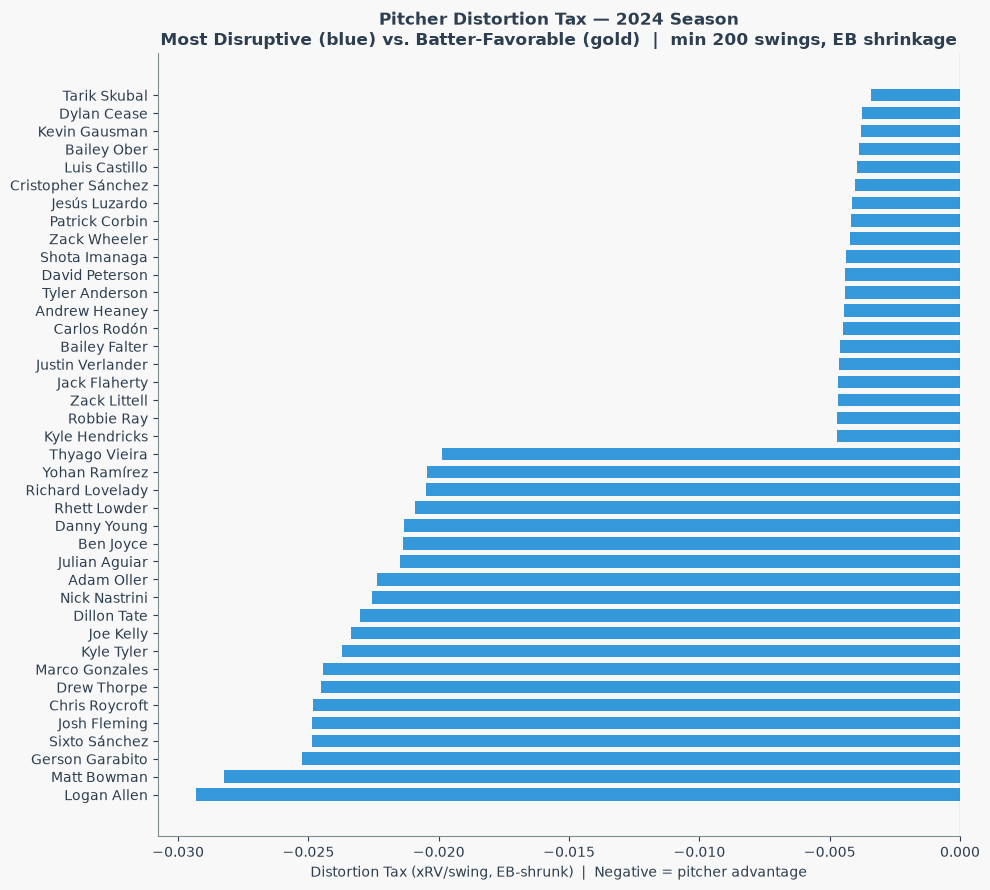

Saved results/plots/leaderboards/distortion_tax_leaderboard_bar.png


In [3]:
csv = Path("results/leaderboard.csv")
if not csv.exists():
    df = merged()
    agg = (df[df["distortion_tax"].notna()]
           .groupby(["pitcher_id", "pitcher_full_name", "game_year"])["distortion_tax"]
           .agg(n="size", mean=np.mean, sd=np.std)
           .reset_index()
           .rename(columns={"mean": "distortion_tax_mean", "sd": "distortion_tax_sd"})
           .query(f"n >= {MIN_SWINGS}"))
    wv = agg["distortion_tax_sd"].pow(2).mean()
    bv = agg["distortion_tax_mean"].var()
    gm = agg["distortion_tax_mean"].mean()
    agg["distortion_tax_shrunk"] = _eb_shrink(agg["distortion_tax_mean"], agg["n"], wv, bv, gm)
    agg.sort_values("distortion_tax_shrunk").to_csv(csv, index=False)

lb   = pd.read_csv(csv)
lb24 = lb[lb["game_year"] == 2024]
show = (pd.concat([lb24.nsmallest(20, "distortion_tax_shrunk"),
                   lb24.nlargest(20,  "distortion_tax_shrunk")])
          .drop_duplicates()
          .sort_values("distortion_tax_shrunk", ascending=True))

fig, ax = plt.subplots(figsize=(10, 9), facecolor=BG)
ax.set_facecolor(BG)
colors = [GOLD if x > 0 else BLUE for x in show["distortion_tax_shrunk"]]
ax.barh(show["pitcher_full_name"], show["distortion_tax_shrunk"], color=colors, height=0.7)
ax.axvline(0, color=DARK, lw=0.8)
ax.set_xlabel("Distortion Tax (xRV/swing, EB-shrunk)  |  Negative = pitcher advantage", color=DARK)
ax.set_title("Pitcher Distortion Tax — 2024 Season\n"
             "Most Disruptive (blue) vs. Batter-Favorable (gold)  |  min 200 swings, EB shrinkage",
             color=DARK, fontweight="bold")
_spine_clean(ax); ax.tick_params(colors=DARK)
fig.tight_layout()
out = "results/plots/leaderboards/distortion_tax_leaderboard_bar.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {out}")


In [ ]:
batters = pd.read_csv("results/distortion_batter.csv").query(f"n_swings >= {MIN_SWINGS}")

# Add names
batter_names = (sxrv_extended()[["batter_id", "batter_full_name"]]
                .drop_duplicates("batter_id"))
batters = batters.merge(batter_names, on="batter_id", how="left")

# Negate: taxes are negative (pitcher advantage); flip for intuitive "susceptibility" direction
batters["distortion_susceptibility"] = -batters["mean_distortion_tax"]
batters["selection_susceptibility"]  = -batters["mean_selection_tax"]

med_d = batters["distortion_susceptibility"].median()
med_s = batters["selection_susceptibility"].median()

fig, ax = plt.subplots(figsize=(8, 7), facecolor=BG)
ax.set_facecolor(BG)
ax.scatter(batters["distortion_susceptibility"], batters["selection_susceptibility"],
           alpha=0.35, s=18, color=BLUE)
ax.axvline(med_d, color=MID, lw=0.8, linestyle="--")
ax.axhline(med_s, color=MID, lw=0.8, linestyle="--")

# Quadrant labels (placed at 90th percentile of each axis)
q90d = batters["distortion_susceptibility"].quantile(0.90)
q90s = batters["selection_susceptibility"].quantile(0.90)
q10d = batters["distortion_susceptibility"].quantile(0.10)
q10s = batters["selection_susceptibility"].quantile(0.10)
ax.text(q90d, q90s, "High both", ha="right", va="top",
        color=RED, fontsize=8, fontstyle="italic")
ax.text(q90d, q10s, "Distortion-dominant\n(mechanical fix)", ha="right", va="bottom",
        color=RED, fontsize=8, fontstyle="italic")
ax.text(q10d, q90s, "Selection-dominant\n(recognition fix)", ha="left", va="top",
        color=GOLD, fontsize=8, fontstyle="italic")

# Annotate top-10 most distortion-susceptible batters
top10 = batters.nlargest(10, "distortion_susceptibility")
for _, row in top10.iterrows():
    last = str(row["batter_full_name"]).split()[-1] if pd.notna(row["batter_full_name"]) else ""
    ax.annotate(last,
                xy=(row["distortion_susceptibility"], row["selection_susceptibility"]),
                xytext=(4, 2), textcoords="offset points",
                fontsize=6, color=DARK)

ax.set_xlabel("Distortion susceptibility (−mean_distortion_tax)", color=DARK)
ax.set_ylabel("Selection susceptibility (−mean_selection_tax)", color=DARK)
ax.set_title(
    f"Batter vulnerability profiles: distortion vs. selection\n"
    f"n = {len(batters)} batters (min {MIN_SWINGS} swings)",
    color=DARK, fontweight="bold")
_spine_clean(ax); ax.tick_params(colors=DARK)
fig.tight_layout()
out = "results/plots/applications/batter_vulnerability.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {out}, n={len(batters)}")

assert Path(out).exists()
assert len(batters) > 100, f"Too few batters: {len(batters)}"
assert (batters["distortion_susceptibility"] > 0).mean() > 0.5

In [ ]:
# Economic Translation
RUNS_PER_WIN  = 10
WAR_SALARY_M  = 8.5  # $M per WAR (2024–2025 market rate)

csv = Path("results/economic_translation.csv")
if not csv.exists():
    pitcher_meta = duckdb.sql("""
        SELECT pitcher_id,
               ANY_VALUE(pitcher_full_name) AS pitcher_full_name,
               AVG(stuff_grade)             AS mean_stuff_grade
        FROM read_parquet('results/swing_xrv.parquet')
        GROUP BY pitcher_id
    """).df()

    eco = (pd.read_csv("results/distortion_pitcher.csv")
           .query(f"n_swings >= {MIN_SWINGS}")
           .merge(pitcher_meta, on="pitcher_id", how="inner"))
    eco["runs_from_distortion"] = eco["mean_distortion_tax"] * eco["n_swings"]
    eco["war_equivalent"]       = eco["runs_from_distortion"].abs() / RUNS_PER_WIN
    eco["dollars_M"]            = eco["war_equivalent"] * WAR_SALARY_M
    eco = eco[["pitcher_id", "pitcher_full_name", "n_swings", "mean_distortion_tax",
              "runs_from_distortion", "war_equivalent", "dollars_M", "mean_stuff_grade"]]
    eco.to_csv(csv, index=False)

eco = pd.read_csv(csv)

top20 = (eco.nsmallest(20, "mean_distortion_tax")
            [["pitcher_full_name", "n_swings", "mean_distortion_tax",
              "runs_from_distortion", "war_equivalent", "dollars_M", "mean_stuff_grade"]]
            .reset_index(drop=True))

# Format for display
tbl_display = top20.copy()
tbl_display["mean_distortion_tax"]  = tbl_display["mean_distortion_tax"].map("{:.4f}".format)
tbl_display["runs_from_distortion"] = tbl_display["runs_from_distortion"].map("{:.1f}".format)
tbl_display["war_equivalent"]       = tbl_display["war_equivalent"].map("{:.1f}".format)
tbl_display["dollars_M"]            = tbl_display["dollars_M"].map("${:.0f}M".format)
tbl_display["mean_stuff_grade"]     = tbl_display["mean_stuff_grade"].map("{:.1f}".format)
tbl_display.columns = ["Pitcher", "Swings", "Distortion Tax\n(xRV/swing)",
                   "Distortion\nRuns", "WAR\nEquiv.", "Value\n($M)", "Stuff+\nGrade"]

fig, ax = plt.subplots(figsize=(13, 8), facecolor=BG)
ax.set_facecolor(BG); ax.axis("off")
tbl = ax.table(cellText=tbl_display.values, colLabels=tbl_display.columns,
               cellLoc="center", loc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5); tbl.scale(1, 1.6)
for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor(MID)
    cell.set_text_props(color=DARK)
    if row == 0:
        cell.set_facecolor(DARK); cell.set_text_props(color="white", fontweight="bold")
    else:
        cell.set_facecolor(BG if row % 2 == 1 else "#ececec")

ax.set_title(
    f"Top 20 pitchers by distortion tax — career 2023–2025\n"
    f"Distortion Runs = mean_distortion_tax × n_swings  |  "
    f"WAR @ {RUNS_PER_WIN} runs/win  |  Value @ ${WAR_SALARY_M}M/WAR",
    color=DARK, fontweight="bold", pad=20)
fig.tight_layout()
out = "results/plots/applications/economic_translation.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {out}")

assert csv.exists()
assert eco["runs_from_distortion"].min() < -20, "Top pitchers should show >20 distortion runs"
assert eco["dollars_M"].max() > 15, "WAR translation should show >$15M for top pitchers"
assert eco["mean_stuff_grade"].std() > 5, "Stuff+ grades should vary across top distortion pitchers"
print("All assertions passed.")